# Questão 1 — MLP para aproximação de função e regressão

**Aprendizado Profundo (UFPB, 2026.2)**

Neste notebook resolvemos a Questão 1 da lista usando uma **Rede Perceptron de Múltiplas Camadas (MLP)** em PyTorch:

- **Parte a)** aproximar a função $f(x) = 3\sin(2x) + 2\cos(5x) + 0{,}5x^2$, com $0 \le x \le 10$.
- **Parte b)** prever a progressão do diabetes com o *Diabetes Dataset* do scikit-learn (regressão).

Em ambas as partes seguimos o mesmo roteiro: preparar os dados, definir a rede, treinar, olhar as curvas de erro e medir **MAE**, **MSE** e **RMSE**.

## 0. Preparação

Importamos as bibliotecas, fixamos as sementes aleatórias (para os resultados serem reproduzíveis por todo o grupo) e definimos duas funções auxiliares que serão usadas nas duas partes:

- `metricas`: calcula MAE, MSE e RMSE.
- `treinar`: laço de treinamento que guarda o erro de treino e o de validação a cada época.

In [1]:
import copy
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
plt.rcParams["figure.dpi"] = 100


def para_tensor(a):
    return torch.tensor(a, dtype=torch.float32)


def metricas(y_real, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    return {"MAE": mean_absolute_error(y_real, y_pred), "MSE": mse, "RMSE": np.sqrt(mse)}


def treinar(modelo, X_tr, y_tr, X_val, y_val, epocas, lr, weight_decay=0.0, batch_size=None, restaurar_melhor=False):
    """Treina com Adam e MSE. batch_size=None usa o lote completo. Retorna o histórico de erros por época."""
    otimizador = torch.optim.Adam(modelo.parameters(), lr=lr, weight_decay=weight_decay)
    perda = nn.MSELoss()
    hist = {"treino": [], "validacao": []}
    melhor_val, melhores_pesos = float("inf"), None

    for _ in range(epocas):
        modelo.train()
        n = len(X_tr)
        lotes = [torch.arange(n)] if batch_size is None or batch_size >= n else torch.randperm(n).split(batch_size)
        erros_lote = []
        for idx in lotes:
            otimizador.zero_grad()
            erro_lote = perda(modelo(X_tr[idx]), y_tr[idx])
            erro_lote.backward()
            otimizador.step()
            erros_lote.append(erro_lote.item())
        erro_tr = np.mean(erros_lote)

        modelo.eval()
        with torch.no_grad():
            erro_val = perda(modelo(X_val), y_val).item()
        hist["treino"].append(erro_tr)
        hist["validacao"].append(erro_val)

        if erro_val < melhor_val:
            melhor_val, melhores_pesos = erro_val, copy.deepcopy(modelo.state_dict())

    if restaurar_melhor:
        modelo.load_state_dict(melhores_pesos)
    return hist


def plotar_curvas(hist, titulo):
    plt.figure(figsize=(7, 4))
    plt.plot(hist["treino"], label="Treino")
    plt.plot(hist["validacao"], label="Validação")
    melhor = int(np.argmin(hist["validacao"]))
    plt.axvline(melhor, color="grey", linestyle="--", alpha=0.7)
    plt.scatter(melhor, hist["validacao"][melhor], color="red", s=40, zorder=5, label=f"Menor erro de validação (época {melhor + 1})")
    plt.yscale("log")
    plt.xlabel("Época")
    plt.ylabel("Erro (MSE, escala normalizada, log)")
    plt.title(titulo)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

**O que foi feito:** o notebook está pronto para uso. O treinamento pode usar o *lote completo* (todos os dados de treino de uma vez a cada época, o padrão) ou *mini-lotes*; a parte a) usa lote completo e, na parte b), o tamanho do lote será um dos hiperparâmetros testados. Nas curvas, a linha tracejada marca a época de menor erro de validação. Todas as curvas de erro usam escala logarítmica no eixo y, porque o erro cai várias ordens de grandeza.

---
# Parte a) Aproximação da função $f(x) = 3\sin(2x) + 2\cos(5x) + 0{,}5x^2$

## a.1 Geração dos dados

Definimos a função e sorteamos **10.000 valores de $x$** uniformemente em $[0, 10]$. A saída desejada é $f(x)$. Como os dados são gerados por nós, podemos escolher quantos queremos, e esse número importa: pela Regra de Ouro, quanto mais amostras, maior a rede permitida (veja a.3). Separamos **80% para treino (8000)** e **20% para teste (2000)**: a rede só aprende com o treino, e o teste serve para acompanhar o desempenho durante o treinamento (como pede o enunciado).

Treino: 8000 amostras | Teste: 2000 amostras


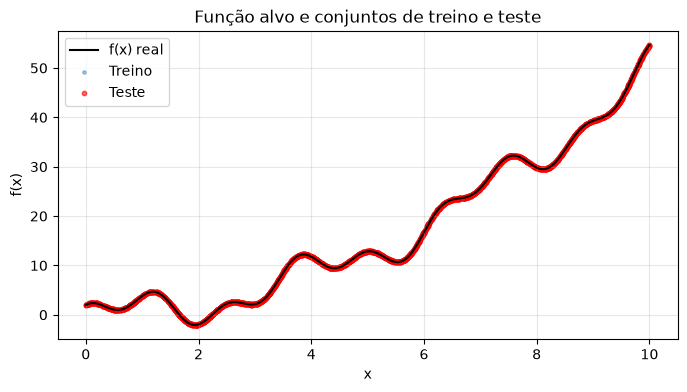

In [2]:
def f(x):
    return 3 * np.sin(2 * x) + 2 * np.cos(5 * x) + 0.5 * x**2


x = np.random.uniform(0, 10, size=(10_000, 1))
y = f(x)

x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=0.2, random_state=SEED)
print(f"Treino: {len(x_tr)} amostras | Teste: {len(x_te)} amostras")

x_grade = np.linspace(0, 10, 500).reshape(-1, 1)  # grade fina, só para desenhar curvas
plt.figure(figsize=(8, 4))
plt.plot(x_grade, f(x_grade), color="black", label="f(x) real")
plt.scatter(x_tr, y_tr, s=6, alpha=0.4, label="Treino")
plt.scatter(x_te, y_te, s=10, color="red", alpha=0.6, label="Teste")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Função alvo e conjuntos de treino e teste")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Resultado:** a função tem uma tendência crescente (o termo $0{,}5x^2$) com oscilações rápidas por cima (os termos seno e cosseno). É isso que a MLP precisa capturar. Os pontos de treino e de teste cobrem todo o intervalo.

## a.2 Normalização

Redes neurais treinam melhor quando entradas e saídas têm escala parecida (média 0, desvio 1). Aplicamos `StandardScaler` em $x$ e em $f(x)$, **ajustando os scalers apenas com o treino** para não vazar informação do teste. Quando formos calcular as métricas, voltamos para a escala original.

In [3]:
sc_x = StandardScaler().fit(x_tr)
sc_y = StandardScaler().fit(y_tr)

X_tr, X_te = para_tensor(sc_x.transform(x_tr)), para_tensor(sc_x.transform(x_te))
Y_tr, Y_te = para_tensor(sc_y.transform(y_tr)), para_tensor(sc_y.transform(y_te))
print("Média e desvio de x (treino):", sc_x.mean_[0].round(2), sc_x.scale_[0].round(2))
print("Média e desvio de f(x) (treino):", sc_y.mean_[0].round(2), sc_y.scale_[0].round(2))

Média e desvio de x (treino): 4.93 2.88
Média e desvio de f(x) (treino): 16.38 14.65


**Resultado:** guardamos a média e o desvio do treino. Os tensores `X_*` e `Y_*` são os dados normalizados que a rede vai usar.

## a.3 Arquitetura da rede (Regra de Ouro da Generalização)

Em vez de escolher o número de neurônios por tentativa e erro, usamos um critério matemático baseado na Teoria da Generalização.

### Dimensão VC e número de pesos

A Teoria Estatística do Aprendizado de Vapnik-Chervonenkis (VC) demonstra que a capacidade de aprendizado de um modelo é proporcional à sua Dimensão VC ($d_{vc}$). Em Redes Neurais, a $d_{vc}$ pode ser aproximada pelo número total de pesos e viéses da rede, ou seja, $d_{vc} \approx |W|$.

### Regra de Ouro da Generalização

Para evitar *overfitting* (memorização dos dados de treino em vez de aprendizado do padrão real), a **Regra de Ouro da Generalização** estabelece que precisamos ter no mínimo 10 exemplos de treinamento independentes para cada parâmetro ajustável (peso) da rede:

$$N \ge 10 \cdot d_{vc} \implies N \ge 10 \cdot |W|$$

### Escolha de uma camada escondida

Optamos por uma rede com **uma única camada escondida**, fundamentados no **Teorema da Aproximação Universal** (Cybenko, 1989; Hornik, 1991): uma rede *feedforward* com uma única camada escondida contendo um número finito de neurônios já é suficiente para aproximar qualquer função contínua em um subconjunto compacto de $\mathbb{R}^n$. Adicionar mais camadas aumenta a dimensão VC sem necessidade teórica, dificultando a generalização. Portanto, usaremos a arquitetura mais simples:

- Entrada com $d$ neurônios (*features*)
- 1 camada escondida com $n$ neurônios
- Saída com 1 neurônio (como nossos problemas são de **regressão**, a saída é um valor contínuo)

### Cálculo do número máximo de neurônios ($n_{max}$)

Para a arquitetura de uma camada escondida com $d$ entradas e 1 saída, o número total de pesos $|W|$ é dado por:

- Pesos da camada escondida: $(d \cdot n)$ pesos + $n$ viéses
- Pesos da camada de saída: $(n \cdot 1)$ pesos + $1$ viés

$$|W| = (d + 1) \cdot n + (n + 1)$$

Substituindo na Regra de Ouro $N \ge 10 \cdot |W|$ e isolando $n$:

$$N \ge 10 \cdot [(d + 1)n + (n + 1)]$$

$$N \ge 10(d + 1)n + 10n + 10$$

$$N - 10 \ge 10n(d + 2)$$

$$\boxed{n \le \frac{N - 10}{10(d + 2)}}$$

**Observação:** a Regra de Ouro é uma regra prática, derivada da teoria, e não um teorema exato. Ela é conservadora e fornece um **limite superior** para $n$, não o valor ideal. As duas fórmulas acima viram duas funções simples, definidas logo abaixo e usadas também na parte b).

In [4]:
def n_pesos(d, n):
    # |W| = (d + 1) * n + (n + 1): pesos e viéses da escondida e da saída
    return (d + 1) * n + (n + 1)


def n_neuronios_max(N, d):
    # n <= (N - 10) / (10 * (d + 2)), arredondado para baixo (margem de segurança)
    return int((N - 10) // (10 * (d + 2)))

**O que foi feito:** definimos `n_pesos` (quantos pesos e viéses a rede tem) e `n_neuronios_max` (quantos neurônios a Regra de Ouro permite). Nenhum resultado ainda: elas são usadas logo abaixo, e de novo na parte b).

### Substituição com os valores reais

Para o nosso problema, extraímos:

- $N = 8000$ amostras de treino
- $d = 1$ atributo (o próprio $x$)

Substituindo na equação teórica:

$$n \le \frac{8000 - 10}{10(1 + 2)} = \frac{7990}{30} \approx 266{,}33$$

Para obter um valor inteiro válido e manter a margem de segurança, arredondamos para baixo: **$n = 266$ neurônios na camada escondida**. O código abaixo repete essas contas (e a verificação do número de pesos) com as funções definidas acima.

In [5]:
N = len(x_tr)
d = x_tr.shape[1]
n_a = n_neuronios_max(N, d)
W_a = n_pesos(d, n_a)

print(f"N = {N} amostras de treino | d = {d} atributo")
print(f"n <= ({N} - 10) / (10 * ({d} + 2)) = {(N - 10) / (10 * (d + 2)):.2f}  ->  n = {n_a}")
print(f"|W| = ({d} + 1) * {n_a} + ({n_a} + 1) = {W_a} pesos")
print(f"Regra de Ouro: N = {N} >= 10 * {W_a} = {10 * W_a}  ->  {'OK' if N >= 10 * W_a else 'VIOLADA'}")

N = 8000 amostras de treino | d = 1 atributo
n <= (8000 - 10) / (10 * (1 + 2)) = 266.33  ->  n = 266
|W| = (1 + 1) * 266 + (266 + 1) = 799 pesos
Regra de Ouro: N = 8000 >= 10 * 799 = 7990  ->  OK


**Resultado:** a rede pode ter até 266 neurônios, o que dá 799 pesos, e $8000 \ge 7990$: a regra é satisfeita (de forma bem justa, como esperado de um arredondamento para baixo).

### Arquitetura final

| Camada | Neurônios | Ativação | Parâmetros |
|---|---|---|---|
| Entrada | 1 | | 0 |
| Escondida | 266 | Tanh | $(1 \cdot 266) + 266 = 532$ |
| Saída | 1 | Linear (nenhuma) | $(266 \cdot 1) + 1 = 267$ |
| **Total** | | | **799** |

A teoria define o **tamanho** da rede, não a ativação. Escolhemos a **tangente hiperbólica (Tanh)** porque a função alvo é suave e oscilante: a ReLU produz curvas lineares por partes e precisaria de mais neurônios para imitar as oscilações. Na saída não há ativação, já que é regressão (um valor contínuo). Treinamos com **Adam** (taxa 0,001, o valor padrão, sem ajuste por validação: como os dados não têm ruído, ela afeta a velocidade de convergência e não a generalização) e erro quadrático médio (**MSE**).

In [6]:
modelo_a = nn.Sequential(
    nn.Linear(1, n_a), nn.Tanh(),
    nn.Linear(n_a, 1),
)
print(modelo_a)
print("Parâmetros treináveis:", sum(p.numel() for p in modelo_a.parameters()))

Sequential(
  (0): Linear(in_features=1, out_features=266, bias=True)
  (1): Tanh()
  (2): Linear(in_features=266, out_features=1, bias=True)
)
Parâmetros treináveis: 799


**Resultado:** a rede construída tem 799 parâmetros, igual ao previsto pela fórmula $|W| = (d+1)n + (n+1)$.

## a.4 Treinamento

Treinamos usando **somente o conjunto de treino**, por **30.000 épocas**. É bastante, porque a rede de uma só camada, com a capacidade limitada pela Regra de Ouro, converge mais devagar. A cada época, calculamos também o erro no conjunto de teste (sem usá-lo para atualizar os pesos), para montar a curva de validação.

In [7]:
hist_a = treinar(modelo_a, X_tr, Y_tr, X_te, Y_te, epocas=30_000, lr=1e-3)
print(f"Erro final (normalizado) -> treino: {hist_a['treino'][-1]:.5f} | teste: {hist_a['validacao'][-1]:.5f}")

Erro final (normalizado) -> treino: 0.00100 | teste: 0.00101


**Resultado:** o erro final é muito pequeno nos dois conjuntos. Vamos ver a evolução ao longo das épocas na próxima seção.

## a.5 Curvas de erro de treinamento e de validação

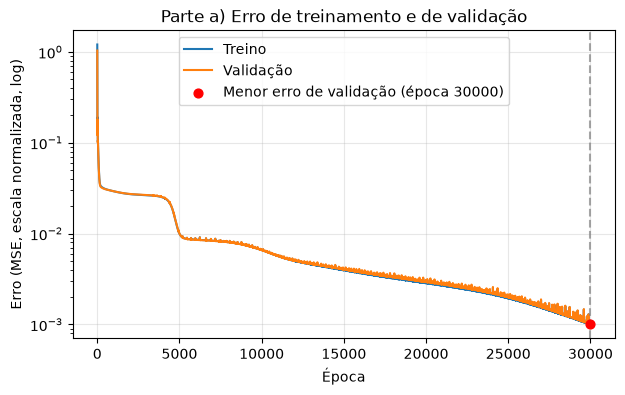

In [8]:
plotar_curvas(hist_a, "Parte a) Erro de treinamento e de validação")

**Análise:** as duas curvas ficam praticamente coladas durante todo o treinamento, o que indica que a rede **generaliza bem** (não há *overfitting*: o erro de teste não se afasta do de treino). Isso já era esperado: com a Regra de Ouro satisfeita e dados sem ruído, a rede não tem como memorizar. Há um patamar até cerca da época 4500, em que a rede captura só a tendência geral (a parábola), uma queda brusca logo depois, quando ela passa a ajustar as oscilações, e então uma descida lenta. O erro **ainda estava caindo** aos 30.000 épocas, então treinar mais reduziria o erro um pouco mais. Não aparecem picos de instabilidade.

## a.6 Função real × função aproximada

Geramos a saída da rede numa grade fina de $x$ e comparamos com a função real.

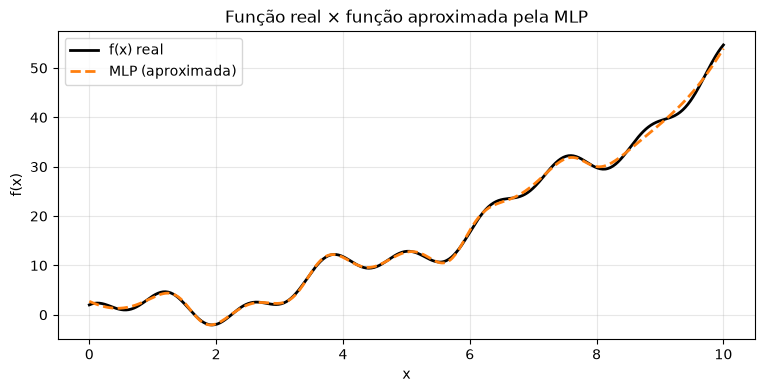

In [9]:
modelo_a.eval()
with torch.no_grad():
    y_grade_pred = sc_y.inverse_transform(modelo_a(para_tensor(sc_x.transform(x_grade))).numpy())

plt.figure(figsize=(9, 4))
plt.plot(x_grade, f(x_grade), color="black", linewidth=2, label="f(x) real")
plt.plot(x_grade, y_grade_pred, color="tab:orange", linestyle="--", linewidth=2, label="MLP (aproximada)")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Função real × função aproximada pela MLP")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Análise:** as duas curvas praticamente se sobrepõem na maior parte do intervalo, inclusive nas oscilações rápidas. As diferenças aparecem nos picos e vales do final (entre $x = 8$ e $x = 10$), onde a função é mais íngreme e oscila mais: ali a rede suaviza um pouco as curvas. A rede aprendeu a tendência e quase todos os detalhes da função.

## a.7 Métricas no conjunto de teste

Convertemos as previsões de volta para a escala original e calculamos **MAE** (erro médio absoluto), **MSE** (erro quadrático médio) e **RMSE** (raiz do MSE, na mesma unidade de $f(x)$). Mostramos também as métricas do treino para comparação.

In [10]:
with torch.no_grad():
    pred_tr = sc_y.inverse_transform(modelo_a(X_tr).numpy())
    pred_te = sc_y.inverse_transform(modelo_a(X_te).numpy())

tabela_a = pd.DataFrame({"Treino": metricas(y_tr, pred_tr), "Teste": metricas(y_te, pred_te)}).T
tabela_a.round(4)

,MAE,MSE,RMSE
Treino,0.3292,0.2147,0.4633
Teste,0.3288,0.2162,0.4650


**Análise:** o erro no teste (RMSE ≈ 0,47) é praticamente igual ao do treino (≈ 0,46), confirmando a boa generalização que a Regra de Ouro prevê. Como $f(x)$ varia de aproximadamente $-2$ a $55$, um RMSE de 0,47 é menos de 1% da amplitude da função. Redes com mais camadas poderiam atingir erros menores, mas teriam bem mais pesos e, pela Regra de Ouro, exigiriam muito mais dados.

## a.8 Curva real × curva predita (conjunto de teste)

Ordenamos os pontos de teste por $x$ para desenhar as curvas. À direita, um gráfico de dispersão do valor real contra o predito: pontos sobre a diagonal significam previsões perfeitas.

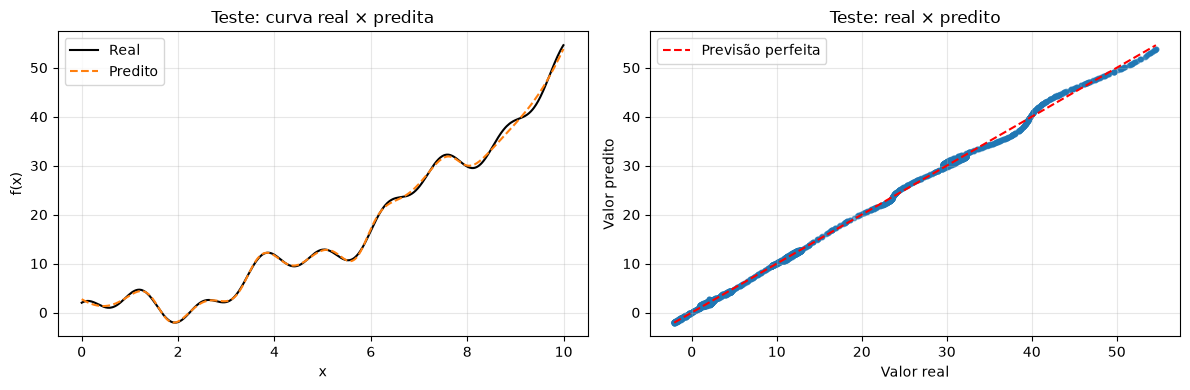

In [11]:
ordem = np.argsort(x_te[:, 0])
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

eixos[0].plot(x_te[ordem], y_te[ordem], color="black", label="Real")
eixos[0].plot(x_te[ordem], pred_te[ordem], color="tab:orange", linestyle="--", label="Predito")
eixos[0].set_xlabel("x")
eixos[0].set_ylabel("f(x)")
eixos[0].set_title("Teste: curva real × predita")
eixos[0].legend()
eixos[0].grid(alpha=0.3)

eixos[1].scatter(y_te, pred_te, s=10, alpha=0.6)
lim = [y_te.min(), y_te.max()]
eixos[1].plot(lim, lim, color="red", linestyle="--", label="Previsão perfeita")
eixos[1].set_xlabel("Valor real")
eixos[1].set_ylabel("Valor predito")
eixos[1].set_title("Teste: real × predito")
eixos[1].legend()
eixos[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Análise:** a curva predita acompanha a real em todos os pontos de teste, e a dispersão fica colada na diagonal. Isso conclui a parte a): a MLP aproxima bem a função.

---
# Parte b) Regressão com o Diabetes Dataset

O dataset tem **442 pacientes**, **10 atributos** (idade, sexo, IMC, pressão arterial e seis medidas de sangue, `s1` a `s6`) e um **alvo quantitativo**: a progressão da doença um ano após a medição inicial. Queremos prever esse alvo a partir dos atributos.

## b.1 Carregamento e análise exploratória

Carregamos com `scaled=False` para ver os atributos nas unidades originais (por padrão o scikit-learn já os entrega centralizados e escalados, o que atrapalharia a exploração). Em seguida olhamos as primeiras linhas, estatísticas descritivas e se há valores ausentes.

In [12]:
dados = load_diabetes(as_frame=True, scaled=False)
df = dados.frame
print("Formato:", df.shape)
print("Valores ausentes por coluna:", int(df.isna().sum().sum()), "no total")
df.head()

Formato: (442, 11)
Valores ausentes por coluna: 0 no total


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


In [13]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,442.0,48.52,13.11,19.00,38.25,50.00,59.00,79.00
sex,442.0,1.47,0.50,1.00,1.00,1.00,2.00,2.00
bmi,442.0,26.38,4.42,18.00,23.20,25.70,29.28,42.20
bp,442.0,94.65,13.83,62.00,84.00,93.00,105.00,133.00
s1,442.0,189.14,34.61,97.00,164.25,186.00,209.75,301.00
s2,442.0,115.44,30.41,41.60,96.05,113.00,134.50,242.40
s3,442.0,49.79,12.93,22.00,40.25,48.00,57.75,99.00
s4,442.0,4.07,1.29,2.00,3.00,4.00,5.00,9.09
s5,442.0,4.64,0.52,3.26,4.28,4.62,5.00,6.11
s6,442.0,91.26,11.50,58.00,83.25,91.00,98.00,124.00


**Resultado:** são 442 linhas e 11 colunas, **sem valores ausentes**, então não precisamos de imputação. Os atributos têm escalas bem diferentes (por exemplo, `age` vai até 79 e `s4` fica em torno de 4), o que justifica a normalização que faremos adiante. A coluna `sex` é binária (1 e 2).

### Distribuições

Histogramas do alvo e de cada atributo, para ver formato e possíveis assimetrias.

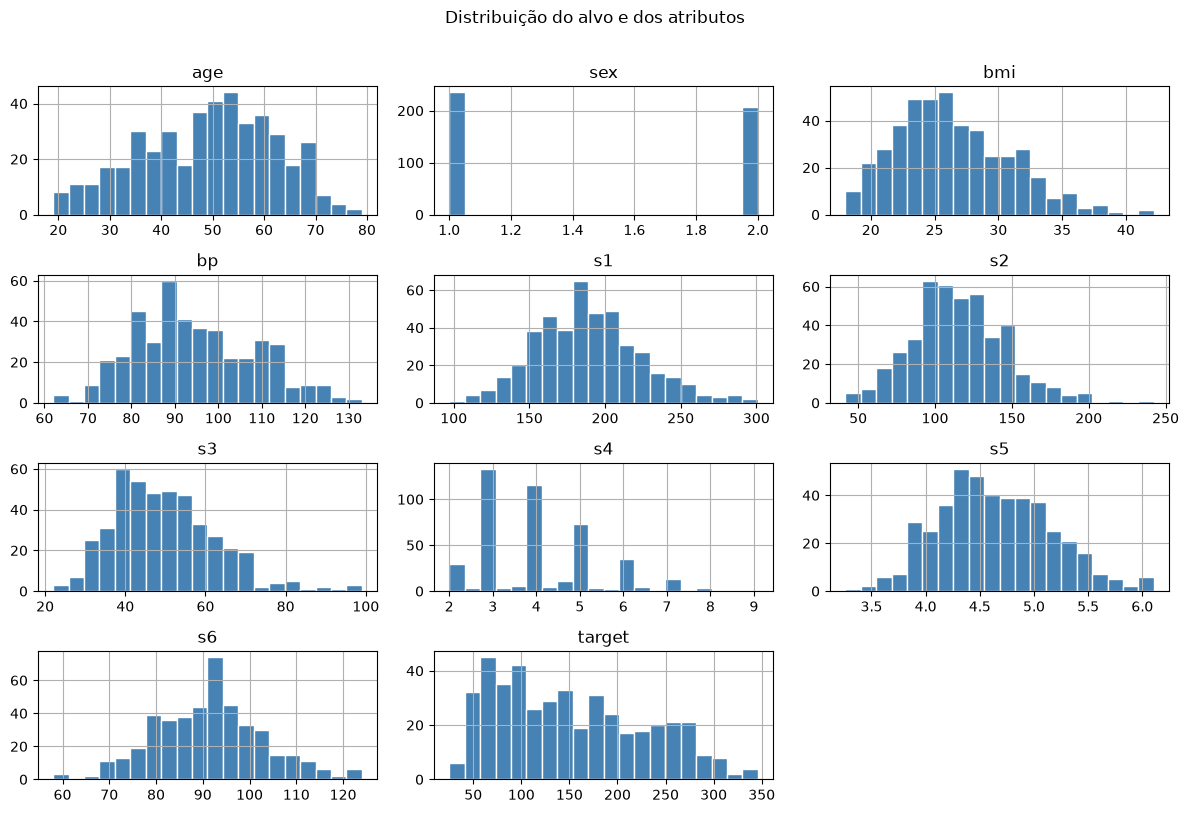

In [14]:
df.hist(bins=20, figsize=(12, 8), color="steelblue", edgecolor="white")
plt.suptitle("Distribuição do alvo e dos atributos", y=1.01)
plt.tight_layout()
plt.show()

**Análise:** o alvo (`target`) tem distribuição um pouco assimétrica à direita: a maioria dos pacientes tem progressão baixa ou moderada e poucos têm valores altos. Os atributos têm formatos variados, e `sex` aparece como duas barras (variável binária). Não há valores absurdos que exijam remoção de *outliers*.

### Correlações

A matriz de correlação mostra quais atributos se relacionam com o alvo e quais se relacionam entre si (atributos muito correlacionados são redundantes).

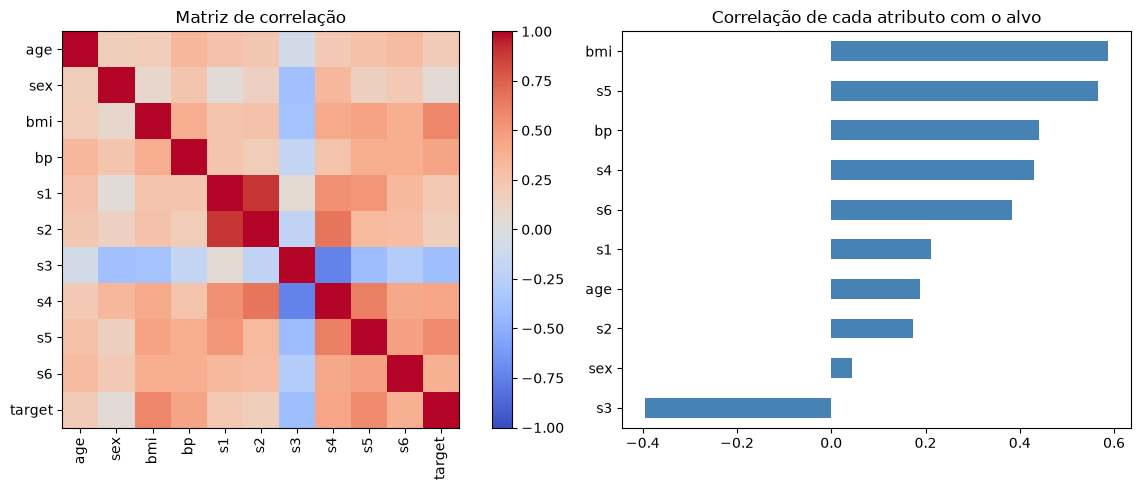

In [15]:
corr = df.corr()
fig, eixos = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.3, 1]})

im = eixos[0].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
eixos[0].set_xticks(range(len(corr)), corr.columns, rotation=90)
eixos[0].set_yticks(range(len(corr)), corr.columns)
eixos[0].set_title("Matriz de correlação")
fig.colorbar(im, ax=eixos[0], fraction=0.046)

corr["target"].drop("target").sort_values().plot.barh(ax=eixos[1], color="steelblue")
eixos[1].set_title("Correlação de cada atributo com o alvo")
plt.tight_layout()
plt.show()

**Análise:** os atributos mais correlacionados com a progressão da doença são `bmi` (IMC), `s5` e `bp` (pressão arterial), todos positivos. Há também forte correlação entre alguns atributos de sangue, como `s1` e `s2`, o que indica certa redundância entre eles; `s3` é o único com correlação negativa relevante com o alvo. Como a MLP aprende combinações dos atributos, mantemos todos.

## b.2 Divisão dos dados e normalização

Como o dataset é pequeno, dividimos em **70% treino, 15% validação e 15% teste**:

- **treino**: ajusta os pesos;
- **validação**: acompanha o treinamento e escolhe a melhor época;
- **teste**: usado só no final, para medir o desempenho real.

Os atributos e o alvo são normalizados com `StandardScaler`, ajustado **somente no treino**. As métricas serão calculadas na escala original do alvo.

In [16]:
X = df.drop(columns="target").values
y = df[["target"]].values

X_tr0, X_tmp, y_tr0, y_tmp = train_test_split(X, y, test_size=0.30, random_state=SEED)
X_va0, X_te0, y_va0, y_te0 = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=SEED)
print(f"Treino: {len(X_tr0)} | Validação: {len(X_va0)} | Teste: {len(X_te0)}")

sc_X_b = StandardScaler().fit(X_tr0)
sc_y_b = StandardScaler().fit(y_tr0)

XB_tr, XB_va, XB_te = (para_tensor(sc_X_b.transform(a)) for a in (X_tr0, X_va0, X_te0))
YB_tr, YB_va, YB_te = (para_tensor(sc_y_b.transform(a)) for a in (y_tr0, y_va0, y_te0))

Treino: 309 | Validação: 66 | Teste: 67


**Resultado:** os três conjuntos estão prontos e normalizados. Os dados de validação e teste foram transformados com a média e o desvio calculados no treino.

## b.3 Arquitetura da rede (Regra de Ouro da Generalização)

Usamos o mesmo critério da parte a), agora com os dados do Diabetes Dataset.

### Dimensão VC e número de pesos

A Teoria Estatística do Aprendizado de Vapnik-Chervonenkis (VC) demonstra que a capacidade de aprendizado de um modelo é proporcional à sua Dimensão VC ($d_{vc}$). Em Redes Neurais, a $d_{vc}$ pode ser aproximada pelo número total de pesos e viéses da rede, ou seja, $d_{vc} \approx |W|$.

### Regra de Ouro da Generalização

Para evitar *overfitting* (memorização dos dados de treino em vez de aprendizado do padrão real), a **Regra de Ouro da Generalização** estabelece que precisamos ter no mínimo 10 exemplos de treinamento independentes para cada parâmetro ajustável (peso) da rede:

$$N \ge 10 \cdot d_{vc} \implies N \ge 10 \cdot |W|$$

### Escolha de uma camada escondida

Optamos por uma rede com **uma única camada escondida**, fundamentados no **Teorema da Aproximação Universal** (Cybenko, 1989; Hornik, 1991): uma rede *feedforward* com uma única camada escondida contendo um número finito de neurônios já é suficiente para aproximar qualquer função contínua em um subconjunto compacto de $\mathbb{R}^n$. Adicionar mais camadas aumenta a dimensão VC sem necessidade teórica, dificultando a generalização. Portanto, usaremos a arquitetura mais simples:

- Entrada com $d$ neurônios (*features*)
- 1 camada escondida com $n$ neurônios
- Saída com 1 neurônio (como nossos problemas são de **regressão**, a saída é um valor contínuo)

### Cálculo do número máximo de neurônios ($n_{max}$)

Para a arquitetura de uma camada escondida com $d$ entradas e 1 saída, o número total de pesos $|W|$ é dado por:

- Pesos da camada escondida: $(d \cdot n)$ pesos + $n$ viéses
- Pesos da camada de saída: $(n \cdot 1)$ pesos + $1$ viés

$$|W| = (d + 1) \cdot n + (n + 1)$$

Substituindo na Regra de Ouro $N \ge 10 \cdot |W|$ e isolando $n$:

$$N \ge 10 \cdot [(d + 1)n + (n + 1)]$$

$$N \ge 10(d + 1)n + 10n + 10$$

$$N - 10 \ge 10n(d + 2)$$

$$\boxed{n \le \frac{N - 10}{10(d + 2)}}$$

**Observação:** a Regra de Ouro é uma regra prática, derivada da teoria, e não um teorema exato. Ela é conservadora e fornece um **limite superior** para $n$, não o valor ideal.

### Substituição com os valores reais

Para o Diabetes Dataset, com a divisão 70/15/15 feita acima, extraímos:

- $N = 309$ amostras de treino
- $d = 10$ atributos

$$n \le \frac{309 - 10}{10(10 + 2)} = \frac{299}{120} \approx 2{,}49$$

Arredondando para baixo: **$n = 2$ neurônios na camada escondida**.

In [17]:
N = len(X_tr0)
d = X_tr0.shape[1]
n_b = n_neuronios_max(N, d)
W_b = n_pesos(d, n_b)

print(f"N = {N} amostras de treino | d = {d} atributos")
print(f"n <= ({N} - 10) / (10 * ({d} + 2)) = {(N - 10) / (10 * (d + 2)):.2f}  ->  n = {n_b}")
print(f"|W| = ({d} + 1) * {n_b} + ({n_b} + 1) = {W_b} pesos")
print(f"Regra de Ouro: N = {N} >= 10 * {W_b} = {10 * W_b}  ->  {'OK' if N >= 10 * W_b else 'VIOLADA'}")

N = 309 amostras de treino | d = 10 atributos
n <= (309 - 10) / (10 * (10 + 2)) = 2.49  ->  n = 2
|W| = (10 + 1) * 2 + (2 + 1) = 25 pesos
Regra de Ouro: N = 309 >= 10 * 25 = 250  ->  OK


**Resultado:** a regra permite apenas 2 neurônios, o que dá 25 pesos, e $309 \ge 250$ é satisfeito. É uma rede muito pequena, mas o dataset também é: com 309 amostras de treino, uma rede maior não teria dados suficientes para ter seus pesos bem determinados.

### Arquitetura final

| Camada | Neurônios | Ativação | Parâmetros |
|---|---|---|---|
| Entrada | 10 | | 0 |
| Escondida | 2 | ReLU | $(10 \cdot 2) + 2 = 22$ |
| Saída | 1 | Linear (nenhuma) | $(2 \cdot 1) + 1 = 3$ |
| **Total** | | | **25** |

Usamos **ReLU** na camada escondida (padrão para dados tabulares) e saída linear, por ser regressão. Treinamos com Adam e MSE (os hiperparâmetros são escolhidos por Grid Search com validação cruzada na seção b.3.1), e restauramos os pesos da melhor época de validação (*early stopping*).

In [18]:
modelo_b = nn.Sequential(
    nn.Linear(d, n_b), nn.ReLU(),
    nn.Linear(n_b, 1),
)
print(modelo_b)
print("Parâmetros treináveis:", sum(p.numel() for p in modelo_b.parameters()))

Sequential(
  (0): Linear(in_features=10, out_features=2, bias=True)
  (1): ReLU()
  (2): Linear(in_features=2, out_features=1, bias=True)
)
Parâmetros treináveis: 25


**Resultado:** 25 parâmetros, como previsto pela fórmula.

### b.3.1 Escolha dos hiperparâmetros (Grid Search com validação cruzada)

A Regra de Ouro define o **tamanho** da rede (2 neurônios), mas não os hiperparâmetros de treinamento. Escolhemos eles com **Grid Search**: testamos todas as combinações de uma grade e ficamos com a de melhor desempenho em **validação cruzada** (*k-fold*). Como o dataset é pequeno, um único conjunto de validação de 66 pacientes é muito ruidoso, e a validação cruzada reduz esse problema.

A grade tem 3 hiperparâmetros:

- **taxa de aprendizado** do Adam: 0,001, 0,01 e 0,1;
- **regularização L2** (`weight_decay`): 0, 0,001 e 0,01;
- **tamanho do lote**: 32 (mini-lotes) ou lote completo.

São $3 \times 3 \times 2 = 18$ combinações. Procedimento (**o conjunto de teste não é usado aqui**):

1. Juntamos treino e validação (375 pacientes).
2. Dividimos em **5 partes (*folds*)**. Para cada combinação, treinamos 5 redes (300 épocas): cada uma usa 4 partes para treinar e 1 para validar.
3. Escolhemos a combinação com **menor RMSE médio** nas partes de validação.

Em cada rede, os atributos e o alvo são normalizados com os dados de treino daquele *fold*, e restauramos os pesos da melhor época, como no treinamento final.

In [19]:
def criar_mlp(n_entrada, ocultas, ativacao=nn.ReLU):
    # Monta uma MLP com as camadas ocultas dadas, p. ex. (2,) ou (32, 16)
    camadas, anterior = [], n_entrada
    for n in ocultas:
        camadas += [nn.Linear(anterior, n), ativacao()]
        anterior = n
    return nn.Sequential(*camadas, nn.Linear(anterior, 1))


EPOCAS_B = 300
X_cv = np.vstack([X_tr0, X_va0])
y_cv = np.vstack([y_tr0, y_va0])
grade = itertools.product([1e-3, 1e-2, 1e-1], [0.0, 1e-3, 1e-2], [32, None])

linhas = []
with torch.random.fork_rng():  # não altera os números sorteados no resto do notebook
    for lr, wd, bs in grade:
        rmses = []
        for i_tr, i_va in KFold(n_splits=5, shuffle=True, random_state=SEED).split(X_cv):
            sx_, sy_ = StandardScaler().fit(X_cv[i_tr]), StandardScaler().fit(y_cv[i_tr])
            Xa, Xv = para_tensor(sx_.transform(X_cv[i_tr])), para_tensor(sx_.transform(X_cv[i_va]))
            Ya, Yv = para_tensor(sy_.transform(y_cv[i_tr])), para_tensor(sy_.transform(y_cv[i_va]))
            torch.manual_seed(SEED)
            m = criar_mlp(d, (n_b,))
            treinar(m, Xa, Ya, Xv, Yv, epocas=EPOCAS_B, lr=lr, weight_decay=wd, batch_size=bs, restaurar_melhor=True)
            with torch.no_grad():
                rmses.append(metricas(y_cv[i_va], sy_.inverse_transform(m(Xv).numpy()))["RMSE"])
        linhas.append({"Taxa": lr, "L2": wd, "Lote": bs if bs else "completo",
                       "RMSE médio (validação)": round(np.mean(rmses), 2),
                       "Desvio entre folds": round(np.std(rmses), 2)})

tabela_gs = pd.DataFrame(linhas).sort_values("RMSE médio (validação)").reset_index(drop=True)
melhor = tabela_gs.iloc[0]
melhor_lr, melhor_wd = melhor["Taxa"], melhor["L2"]
melhor_bs = None if melhor["Lote"] == "completo" else int(melhor["Lote"])
print(f"Melhor combinação: taxa={melhor_lr} | L2={melhor_wd} | lote={melhor['Lote']}")
tabela_gs.head(8)

Melhor combinação: taxa=0.1 | L2=0.01 | lote=32


,Taxa,L2,Lote,RMSE médio (validação),Desvio entre folds
0,0.10,0.010,32,54.26,2.55
1,0.10,0.001,completo,54.53,2.69
2,0.10,0.000,completo,54.55,2.72
3,0.10,0.001,32,54.59,2.43
4,0.10,0.010,completo,54.68,2.41
5,0.10,0.000,32,54.71,2.61
6,0.01,0.001,32,54.90,2.49
7,0.01,0.010,32,54.92,2.54


**Resultado:** a melhor combinação foi **taxa 0,1, L2 de 0,01 e lote de 32**, com RMSE médio de 54,26 na validação, e é ela que usamos no treinamento final. Mas a tabela mostra que a escolha não é conclusiva:

- As 8 melhores combinações ficam entre 54,26 e 54,92, uma diferença de menos de 1 ponto, bem **menor que o desvio entre folds** (cerca de 2,4 a 2,7). Ou seja, os hiperparâmetros testados **empatam dentro do ruído**: com uma rede de 25 pesos, nenhum deles muda muito o resultado.
- Todas as 8 primeiras usam taxas altas (0,1 ou 0,01). A taxa 0,1 está na **borda da grade**: não testamos valores maiores.
- Taxas altas com mini-lotes deixam o treino mais ruidoso, o que aparece nas curvas da seção b.4.

### b.3.2 Verificação: e se a rede fosse maior que o limite?

A regra dá um limite superior, então vale conferir na prática o que acontece ao ultrapassá-lo. Treinamos redes de tamanhos diferentes, com o mesmo treinamento, e repetimos com **5 divisões diferentes** dos dados (sementes 0 a 4), já que o teste tem só ~67 pacientes e uma única divisão pode enganar. A coluna "Regra" indica se o tamanho respeita $N \ge 10|W|$.

In [20]:
def rmse_diabetes(ocultas, seed):
    # Refaz a divisão 70/15/15 com outra semente e treina uma rede nova
    X_a, X_t_, y_a, y_t_ = train_test_split(X, y, test_size=0.30, random_state=seed)
    X_v, X_t, y_v, y_t = train_test_split(X_t_, y_t_, test_size=0.50, random_state=seed)
    sx_, sy_ = StandardScaler().fit(X_a), StandardScaler().fit(y_a)
    XS = [para_tensor(sx_.transform(a)) for a in (X_a, X_v, X_t)]
    YS = [para_tensor(sy_.transform(a)) for a in (y_a, y_v, y_t)]
    torch.manual_seed(seed)
    m = criar_mlp(d, ocultas)
    treinar(m, XS[0], YS[0], XS[1], YS[1], epocas=EPOCAS_B, lr=melhor_lr, weight_decay=melhor_wd, batch_size=melhor_bs, restaurar_melhor=True)
    with torch.no_grad():
        return metricas(y_t, sy_.inverse_transform(m(XS[2]).numpy()))["RMSE"]


linhas = []
with torch.random.fork_rng():  # não altera os números sorteados no resto do notebook
    for ocultas in [(1,), (2,), (4,), (8,), (16,), (32, 16), (64, 64)]:
        rmses = [rmse_diabetes(ocultas, seed) for seed in range(5)]
        n_w = sum(p.numel() for p in criar_mlp(d, ocultas).parameters())
        linhas.append({"Camadas ocultas": ocultas, "Pesos": n_w,
                       "Regra": "OK" if N >= 10 * n_w else "violada",
                       "RMSE médio (teste)": round(np.mean(rmses), 1),
                       "Desvio entre divisões": round(np.std(rmses), 1)})
pd.DataFrame(linhas)

,Camadas ocultas,Pesos,Regra,RMSE médio (teste),Desvio entre divisões
0,"(1,)",13,OK,56.6,4.3
1,"(2,)",25,OK,55.3,3.8
2,"(4,)",49,violada,56.6,3.3
3,"(8,)",97,violada,57.7,3.8
4,"(16,)",193,violada,56.7,3.3
5,"(32, 16)",897,violada,56.1,3.5
6,"(64, 64)",4929,violada,57.7,2.5


**Resultado:** o RMSE médio fica entre 55,3 e 57,7 para **todos** os tamanhos, de uma rede com 13 pesos até uma com 4.929. A variação entre divisões dos dados (desvio de 2,5 a 4,3) é maior que a diferença entre as redes, então **não há evidência de que ultrapassar o limite da regra traga ganho**: as redes que respeitam a regra (1 e 2 neurônios) rendem o mesmo que as muito maiores. Ou seja, a rede pequena escolhida pela regra não perdeu desempenho.

Isso é coerente com o que vimos na seção b.5: o erro da regressão linear também é parecido. Com 309 amostras ruidosas, o que limita o resultado é a informação nos dados, não a capacidade da rede. O RMSE da divisão usada no restante do notebook (semente 42) é 57,4, dentro de um desvio-padrão da média de 55,3 da rede de 2 neurônios.

**Cuidados na leitura:** só testamos 7 tamanhos e 5 divisões, então diferenças de 1 a 2 pontos de RMSE não são significativas.

## b.4 Treinamento e curvas de erro

Treinamos por 300 épocas com Adam e MSE, usando a melhor combinação do Grid Search (taxa, L2 e tamanho do lote da seção b.3.1), e plotamos as curvas de treino e validação. A linha tracejada marca a época de menor erro de validação, cujos pesos são restaurados.

Melhor época (menor erro de validação): 3


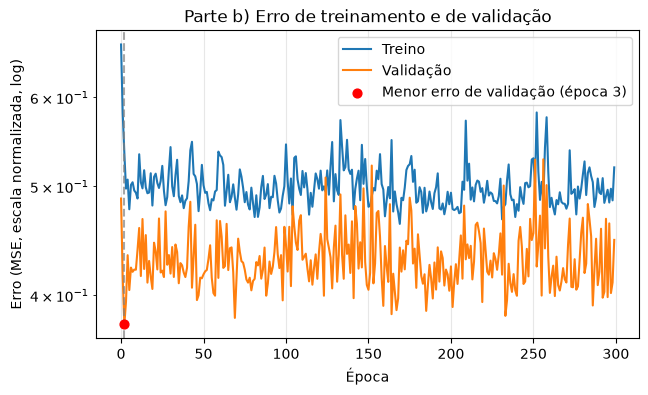

In [21]:
hist_b = treinar(modelo_b, XB_tr, YB_tr, XB_va, YB_va, epocas=EPOCAS_B, lr=melhor_lr, weight_decay=melhor_wd, batch_size=melhor_bs, restaurar_melhor=True)
melhor_epoca = int(np.argmin(hist_b["validacao"])) + 1
print(f"Melhor época (menor erro de validação): {melhor_epoca}")
plotar_curvas(hist_b, "Parte b) Erro de treinamento e de validação")

**Análise:** com a combinação escolhida (taxa 0,1, L2 de 0,01, lote de 32), os dois erros caem em poucas épocas e depois **oscilam em torno de um patamar** (treino ≈ 0,50, validação ≈ 0,43), sem tendência clara de subida ou descida. A oscilação vem da taxa alta combinada com mini-lotes. Com apenas 25 pesos, a rede não tem capacidade para memorizar o treino, então não há *overfitting* visível: o erro de validação não sobe sistematicamente.

**Cuidado com a "melhor época":** o menor erro de validação ocorre na época 3, mas como a curva é praticamente plana e ruidosa, essa época é em boa parte **sorte** (o conjunto de validação tem só 66 pacientes). Ela não indica o ponto onde a rede começa a decorar, como em um caso de *overfitting* claro. Também note que o erro de validação fica **abaixo** do de treino: isso não é um erro, e acontece porque a validação é, por acaso, um pouco mais fácil de prever (RMSE de 48,1 contra 54,8 no treino, na escala original).

## b.5 Métricas e comparação com referências

Calculamos MAE, MSE e RMSE na escala original do alvo para treino, validação e teste. Para dar contexto, comparamos com duas referências simples: **prever sempre a média do treino** (o pior razoável) e uma **regressão linear** (um modelo bem mais simples que a MLP).

In [22]:
modelo_b.eval()
with torch.no_grad():
    previsoes = {nome: sc_y_b.inverse_transform(modelo_b(X_).numpy())
                 for nome, X_ in {"Treino": XB_tr, "Validação": XB_va, "Teste": XB_te}.items()}
reais = {"Treino": y_tr0, "Validação": y_va0, "Teste": y_te0}

tabela_b = pd.DataFrame({n: metricas(reais[n], previsoes[n]) for n in reais}).T

# Referências, avaliadas no teste
media = np.full_like(y_te0, y_tr0.mean())
linear = LinearRegression().fit(sc_X_b.transform(X_tr0), y_tr0).predict(sc_X_b.transform(X_te0))
referencias = pd.DataFrame({"Média do treino (teste)": metricas(y_te0, media),
                            "Regressão linear (teste)": metricas(y_te0, linear)}).T

display(tabela_b.round(2))
display(referencias.round(2))

,MAE,MSE,RMSE
Treino,44.55,2999.63,54.77
Validação,37.64,2316.84,48.13
Teste,46.45,3299.32,57.44


,MAE,MSE,RMSE
Média do treino (teste),66.45,5706.61,75.54
Regressão linear (teste),45.57,3139.37,56.03


**Análise:** o RMSE da MLP no teste (≈ 57) fica bem abaixo do de "prever a média" (≈ 76), então a rede de fato aprendeu algo útil. Mas ele fica um pouco acima do da regressão linear (≈ 56). A diferença é pequena frente à variação entre divisões que medimos na seção b.3.2 (desvio de 2,5 a 4 pontos), então a conclusão correta é que **a MLP e a regressão linear empatam**. Isso é esperado: neste dataset a relação entre os atributos e o alvo é em grande parte linear e há poucos dados, então a não linearidade da MLP não traz ganho.

## b.6 Valores reais × valores preditos

No gráfico de dispersão, cada ponto é um paciente do conjunto de teste. Quanto mais perto da diagonal, melhor a previsão. À direita, os dados ordenados pelo valor real, para comparar as curvas.

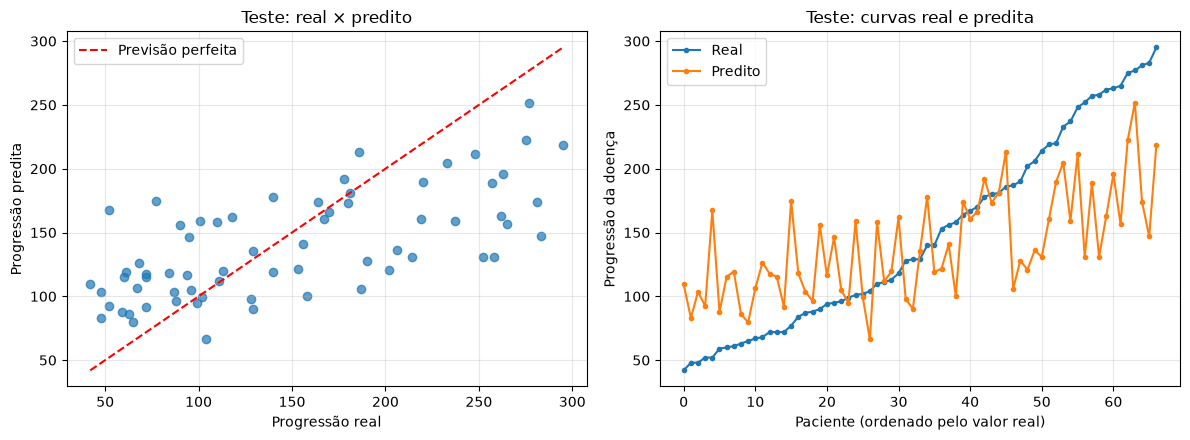

In [23]:
real, pred = y_te0[:, 0], previsoes["Teste"][:, 0]
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))

eixos[0].scatter(real, pred, alpha=0.7)
lim = [real.min(), real.max()]
eixos[0].plot(lim, lim, color="red", linestyle="--", label="Previsão perfeita")
eixos[0].set_xlabel("Progressão real")
eixos[0].set_ylabel("Progressão predita")
eixos[0].set_title("Teste: real × predito")
eixos[0].legend()
eixos[0].grid(alpha=0.3)

ordem = np.argsort(real)
eixos[1].plot(real[ordem], label="Real", marker="o", markersize=3)
eixos[1].plot(pred[ordem], label="Predito", marker="o", markersize=3)
eixos[1].set_xlabel("Paciente (ordenado pelo valor real)")
eixos[1].set_ylabel("Progressão da doença")
eixos[1].set_title("Teste: curvas real e predita")
eixos[1].legend()
eixos[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Análise:** os pontos seguem a tendência da diagonal, mas com bastante dispersão: a rede acerta a direção (pacientes com progressão alta recebem previsões altas), porém erra por dezenas de unidades em vários casos. A rede também tende a "puxar para o meio", subestimando os valores mais altos e superestimando os mais baixos, comportamento comum quando há ruído nos dados e poucas amostras.

---
# Conclusões

- **Dimensionamento:** em vez de escolher o número de neurônios por tentativa e erro, usamos a Regra de Ouro da Generalização ($N \ge 10 \cdot |W|$) com uma única camada escondida, o que leva a $n \le \frac{N - 10}{10(d + 2)}$.
- **Parte a):** com 8000 amostras de treino e 1 entrada, a regra permite 266 neurônios (799 pesos). A MLP com essa arquitetura (Tanh) aproximou a função com RMSE ≈ 0,47 no teste, sem *overfitting*, capturando a tendência quadrática e as oscilações. Como o erro ainda caía aos 30.000 épocas, há margem para melhorar com mais treino.
- **Parte b):** com 309 amostras de treino e 10 atributos, a regra permite só 2 neurônios (25 pesos). A MLP aprendeu a prever a progressão do diabetes bem melhor que um baseline de média (RMSE ≈ 57 contra ≈ 76), com desempenho equivalente ao da regressão linear. Os hiperparâmetros (taxa, L2 e tamanho do lote) foram escolhidos por Grid Search com validação cruzada (5 folds), e as combinações melhores empataram dentro do ruído. Redes maiores, que violam a regra, não melhoraram o resultado.
- A diferença entre as duas partes mostra que o resultado depende muito da natureza do problema: uma função determinística e sem ruído pode ser aproximada com precisão altíssima (e basta gerar mais dados para permitir uma rede maior), enquanto dados reais têm erro irredutível e poucas amostras.